<a href="https://colab.research.google.com/github/endy24ti-commits/Belajar_laravel/blob/main/Analisis_Deskriptif_Pima_Indians_Diabetes_Lengkap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Deskriptif Dataset Pima Indians Diabetes

**Mata kuliah:** Probabilitas dan Statistika  
**Objek analisis:** Data medis pasien dan kategori `Outcome`  
**Tujuan:** Menggambarkan karakteristik data melalui statistika deskriptif dan grafik.

Notebook ini disusun mengikuti pola notebook contoh: persiapan, pemeriksaan data, statistika deskriptif, visualisasi, dan ringkasan pembahasan. Isi disesuaikan dengan dataset Pima Indians Diabetes.

**Batasan analisis:** tidak menggunakan uji hipotesis, uji normalitas, uji beda, pengujian korelasi, atau model prediksi. Tidak ada heatmap, scatter plot, maupun grafik jumlah data kosong. Nilai kosong tidak otomatis diisi atau dihapus dari dataset asli; statistik tiap variabel dihitung dari nilai yang tersedia.

## 0. Persiapan

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

os.makedirs("gambar", exist_ok=True)
os.makedirs("tabel", exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

FAKTOR_MEDIS = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"
]
TARGET = "Outcome"
LABEL_OUTCOME = {0: "Non-Diabetes", 1: "Diabetes"}
WARNA_OUTCOME = {0: "#4472C4", 1: "#ED7D31"}

def simpan_gambar(nama):
    plt.savefig(f"gambar/{nama}.png", dpi=300, bbox_inches="tight")

print("Persiapan selesai.")

Persiapan selesai.


## 1. Pemuatan dan pemeriksaan data

Dataset dibaca dari file Excel. Unggah file `3TID_06_Pima_Indians_Diabetes.xlsx` saat diminta oleh Colab.

In [ ]:
uploaded = files.upload()
nama_file = next(iter(uploaded))
df = pd.read_excel(nama_file)
df.columns = df.columns.str.strip()

kolom_wajib = FAKTOR_MEDIS + [TARGET]
kolom_tidak_ada = [k for k in kolom_wajib if k not in df.columns]
if kolom_tidak_ada:
    raise ValueError(f"Kolom tidak ditemukan: {kolom_tidak_ada}")

for kolom in kolom_wajib:
    df[kolom] = pd.to_numeric(df[kolom], errors="coerce")

print("Ukuran dataset:", df.shape)
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
display(df.head())

Saving 3TID_06_Pima_Indians_Diabetes.xlsx to 3TID_06_Pima_Indians_Diabetes.xlsx
Ukuran dataset: (768, 9)
Jumlah baris: 768
Jumlah kolom: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [ ]:
print("Informasi tipe data:")
df.info()

pemeriksaan = pd.DataFrame({
    "Tipe Data": df.dtypes.astype(str),
    "Data Valid": df.count(),
    "Data Kosong": df.isna().sum(),
    "Persentase Kosong (%)": (df.isna().mean() * 100).round(2)
})
display(pemeriksaan)
print("Jumlah baris duplikat:", df.duplicated().sum())

Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


,Tipe Data,Data Valid,Data Kosong,Persentase Kosong (%)
Pregnancies,int64,768,0,0.00
Glucose,float64,763,5,0.65
BloodPressure,float64,733,35,4.56
SkinThickness,float64,541,227,29.56
Insulin,float64,394,374,48.70
BMI,float64,757,11,1.43
DiabetesPedigreeFunction,float64,768,0,0.00
Age,int64,768,0,0.00
Outcome,int64,768,0,0.00


Jumlah baris duplikat: 0


In [ ]:
print("Jumlah data Outcome:")
jumlah_outcome = df[TARGET].value_counts().sort_index()
tabel_outcome = pd.DataFrame({
    "Kategori": [LABEL_OUTCOME.get(i, str(i)) for i in jumlah_outcome.index],
    "Jumlah": jumlah_outcome.values,
    "Persentase (%)": (jumlah_outcome.values / jumlah_outcome.sum() * 100).round(2)
})
display(tabel_outcome)
tabel_outcome.to_csv("tabel/tabel_distribusi_outcome.csv", index=False)

Jumlah data Outcome:


,Kategori,Jumlah,Persentase (%)
0,Non-Diabetes,500,65.1
1,Diabetes,268,34.9


## 2. Statistika deskriptif

Bagian ini menghitung seluruh ukuran yang diminta: Count, Sum, Mean, Median, Modus, Std, Var, Min, Max, Range, Q1, Q3, Skewness, dan Kurtosis. Kuartil Q2 tidak dibuat sebagai kolom terpisah karena sama dengan median.

In [ ]:
baris_statistik = []
for kolom in FAKTOR_MEDIS:
    s = df[kolom].dropna()
    modus = s.mode()
    baris_statistik.append({
        "Faktor Medis": kolom,
        "Count": s.count(),
        "Sum": s.sum(),
        "Mean": s.mean(),
        "Median": s.median(),
        "Modus": modus.iloc[0] if not modus.empty else np.nan,
        "Std": s.std(),
        "Var": s.var(),
        "Min": s.min(),
        "Max": s.max(),
        "Range": s.max() - s.min(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "Skewness": s.skew(),
        "Kurtosis": s.kurt()
    })

tabel_statistik = pd.DataFrame(baris_statistik).set_index("Faktor Medis")
display(tabel_statistik.round(3))
tabel_statistik.to_csv("tabel/tabel_statistika_deskriptif.csv")

,Count,Sum,Mean,Median,Modus,Std,Var,Min,Max,Range,Q1,Q3,Skewness,Kurtosis
Faktor Medis,,,,,,,,,,,,,,
Pregnancies,768,2953.000,3.845,3.000,1.000,3.370,11.354,0.000,17.00,17.000,1.000,6.000,0.902,0.159
Glucose,763,92847.000,121.687,117.000,99.000,30.536,932.425,44.000,199.00,155.000,99.000,141.000,0.531,-0.277
BloodPressure,733,53073.000,72.405,72.000,70.000,12.382,153.318,24.000,122.00,98.000,64.000,80.000,0.134,0.911
SkinThickness,541,15772.000,29.153,29.000,32.000,10.477,109.767,7.000,99.00,92.000,22.000,36.000,0.691,2.935
Insulin,394,61286.000,155.548,125.000,105.000,118.776,14107.704,14.000,846.00,832.000,76.250,190.000,2.166,6.371
BMI,757,24570.300,32.457,32.300,32.000,6.925,47.955,18.200,67.10,48.900,27.500,36.600,0.594,0.863
DiabetesPedigreeFunction,768,362.401,0.472,0.372,0.254,0.331,0.110,0.078,2.42,2.342,0.244,0.626,1.920,5.595
Age,768,25529.000,33.241,29.000,22.000,11.760,138.303,21.000,81.00,60.000,24.000,41.000,1.130,0.643


### 2.1 Ringkasan berdasarkan kategori Outcome

Tabel berikut membandingkan ukuran deskriptif tiap faktor medis untuk kategori Outcome 0 dan 1. Ini merupakan ringkasan deskriptif, bukan pengujian beda kelompok.

In [ ]:
ringkasan_outcome = []
for kolom in FAKTOR_MEDIS:
    for nilai in [0, 1]:
        s = df.loc[df[TARGET] == nilai, kolom].dropna()
        ringkasan_outcome.append({
            "Faktor Medis": kolom,
            "Outcome": LABEL_OUTCOME[nilai],
            "Count": s.count(),
            "Mean": s.mean(),
            "Median": s.median(),
            "Std": s.std(),
            "Min": s.min(),
            "Q1": s.quantile(.25),
            "Q3": s.quantile(.75),
            "Max": s.max()
        })
tabel_ringkasan_outcome = pd.DataFrame(ringkasan_outcome)
display(tabel_ringkasan_outcome.round(3))
tabel_ringkasan_outcome.to_csv("tabel/ringkasan_deskriptif_per_outcome.csv", index=False)

,Faktor Medis,Outcome,Count,Mean,Median,Std,Min,Q1,Q3,Max
0,Pregnancies,Non-Diabetes,500,3.298,2.000,3.017,0.000,1.000,5.000,13.000
1,Pregnancies,Diabetes,268,4.866,4.000,3.741,0.000,1.750,8.000,17.000
2,Glucose,Non-Diabetes,497,110.644,107.000,24.777,44.000,93.000,125.000,197.000
3,Glucose,Diabetes,266,142.320,140.000,29.599,78.000,119.000,167.000,199.000
4,BloodPressure,Non-Diabetes,481,70.877,70.000,12.161,24.000,62.000,78.000,122.000
5,BloodPressure,Diabetes,252,75.321,74.500,12.300,30.000,68.000,84.000,114.000
6,SkinThickness,Non-Diabetes,361,27.235,27.000,10.026,7.000,19.000,33.000,60.000
7,SkinThickness,Diabetes,180,33.000,32.000,10.328,7.000,27.000,39.000,99.000
8,Insulin,Non-Diabetes,264,130.288,102.500,102.482,15.000,66.000,161.250,744.000
9,Insulin,Diabetes,130,206.846,169.500,132.700,14.000,127.500,239.250,846.000


## 3. Visualisasi distribusi data

### 3.1 Histogram setiap faktor medis (8 grafik)
Histogram digunakan untuk melihat frekuensi dan bentuk sebaran masing-masing variabel. Garis KDE membantu memperlihatkan bentuk sebaran secara halus; tidak digunakan sebagai uji statistik.

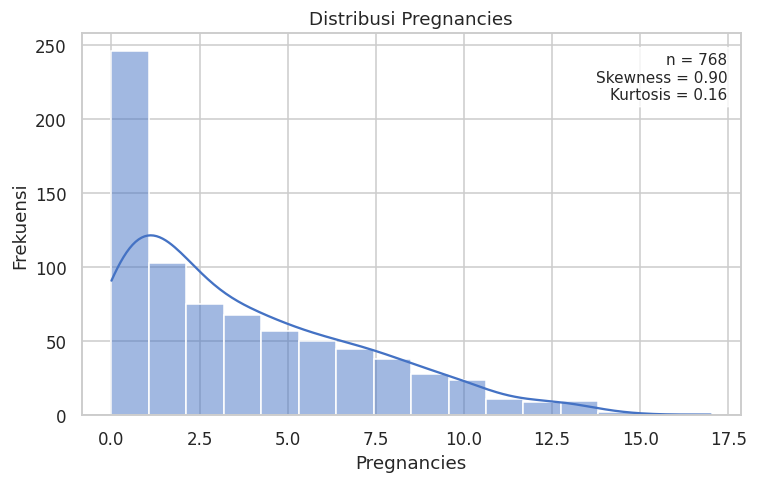

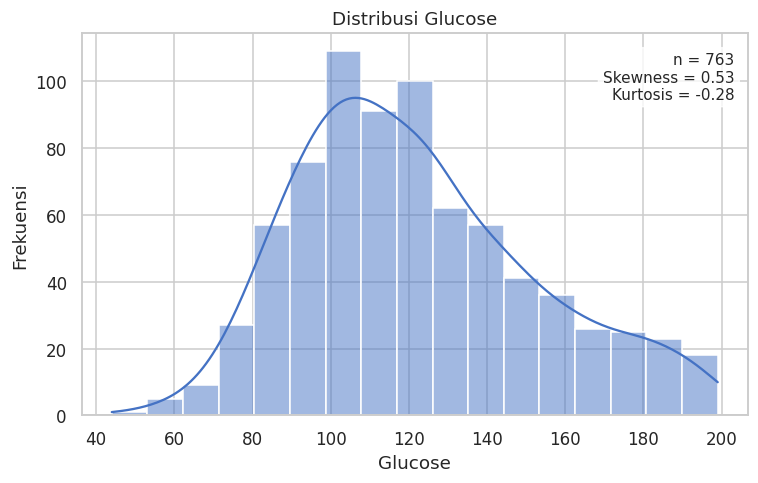

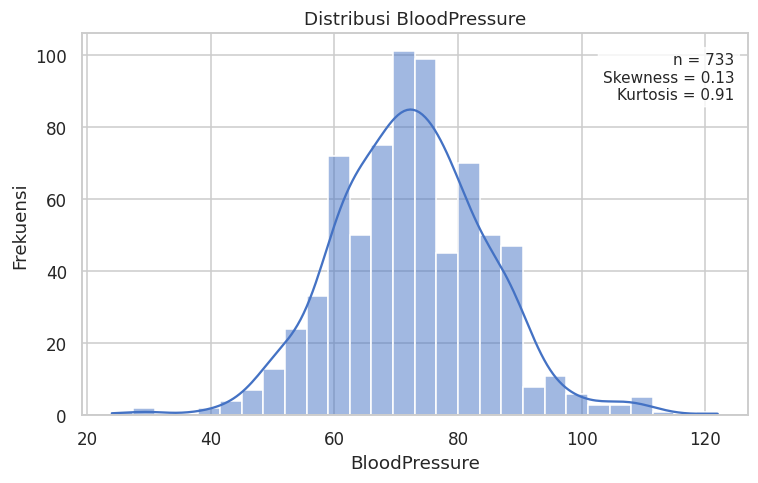

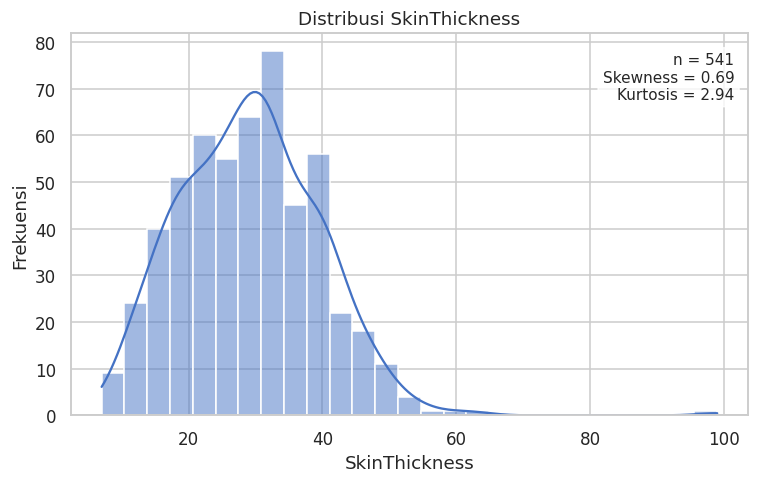

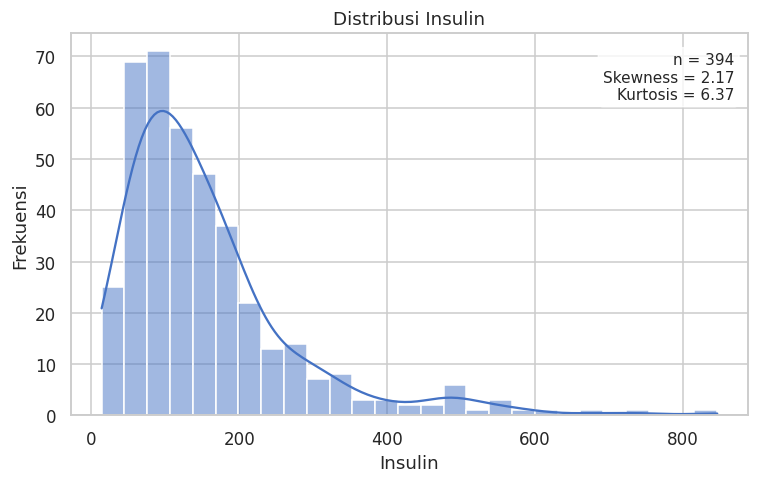

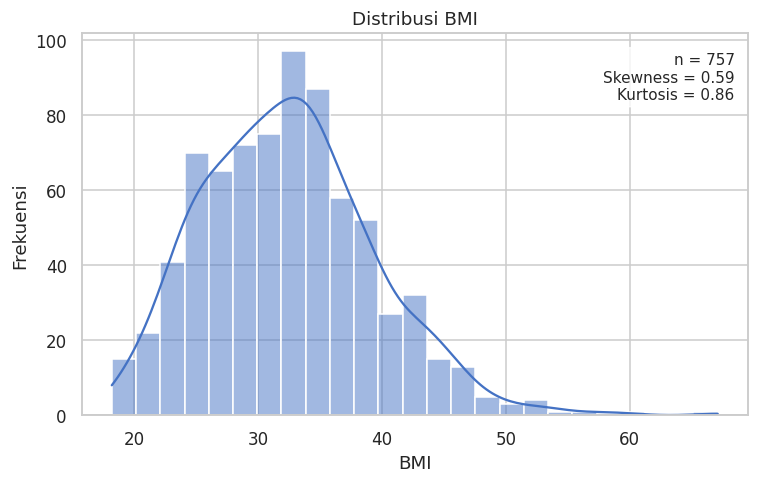

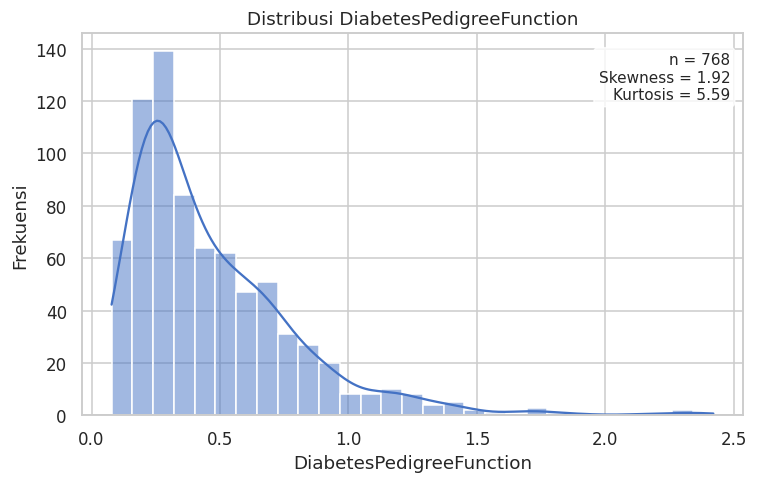

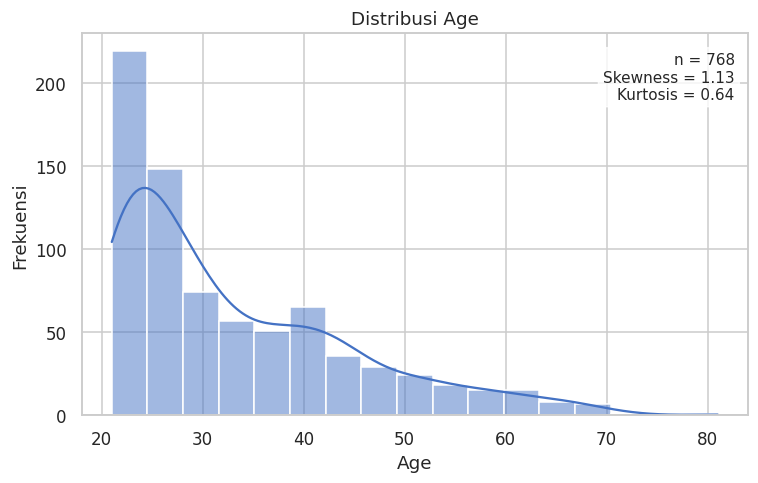

In [ ]:
for kolom in FAKTOR_MEDIS:
    data = df[kolom].dropna()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.histplot(data=data, bins="auto", kde=True, color="#4472C4", ax=ax)
    ax.set_title(f"Distribusi {kolom}")
    ax.set_xlabel(kolom)
    ax.set_ylabel("Frekuensi")
    ax.text(0.98, 0.95,
            f"n = {len(data)}\nSkewness = {data.skew():.2f}\nKurtosis = {data.kurt():.2f}",
            transform=ax.transAxes, ha="right", va="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    plt.tight_layout()
    simpan_gambar(f"histogram_{kolom}")
    plt.show()

### 3.2 Boxplot setiap faktor medis berdasarkan Outcome (8 grafik)
Boxplot memperlihatkan median, Q1, Q3, rentang whisker, dan kemungkinan pencilan. Kedua kategori Outcome ditampilkan berdampingan untuk memudahkan perbandingan deskriptif.

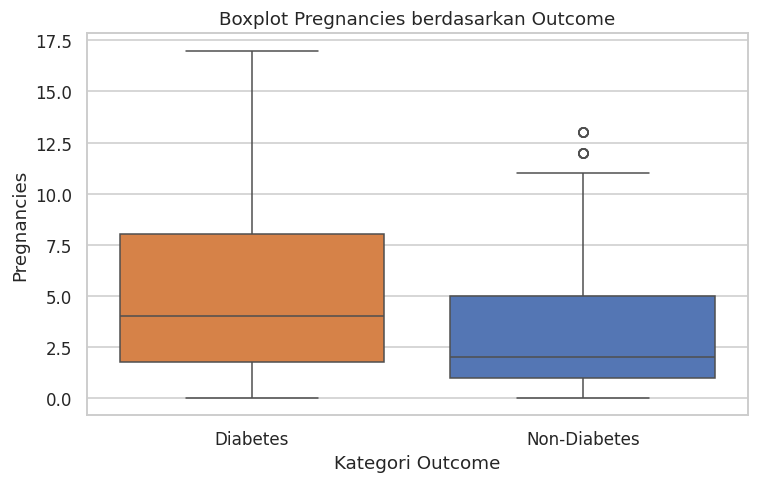

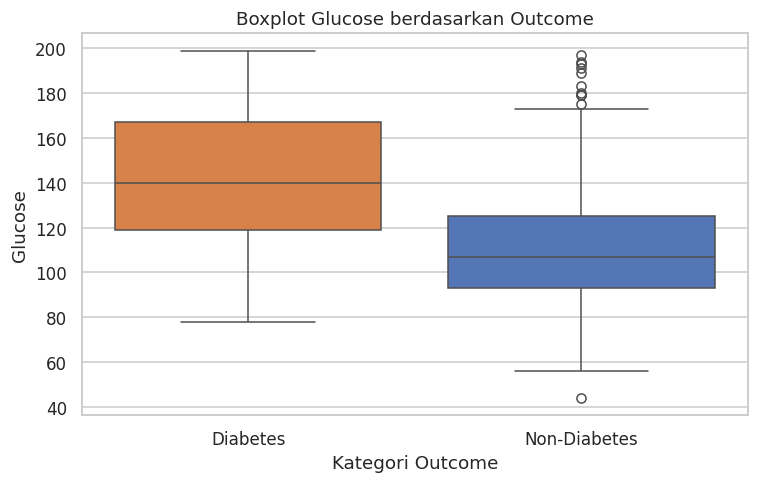

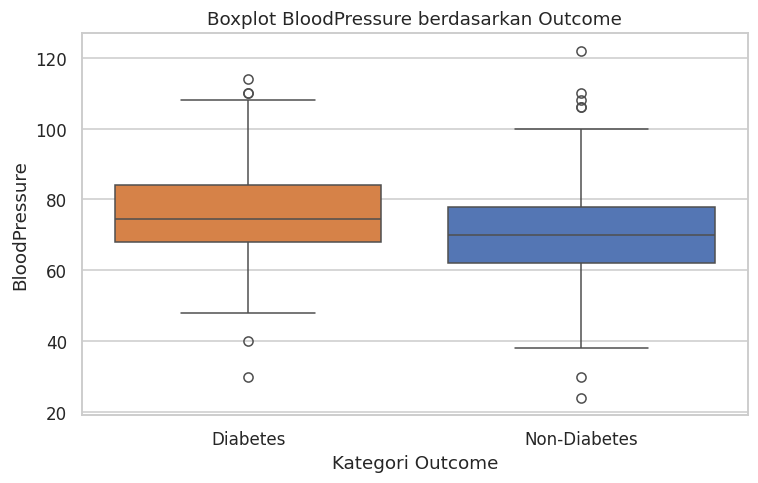

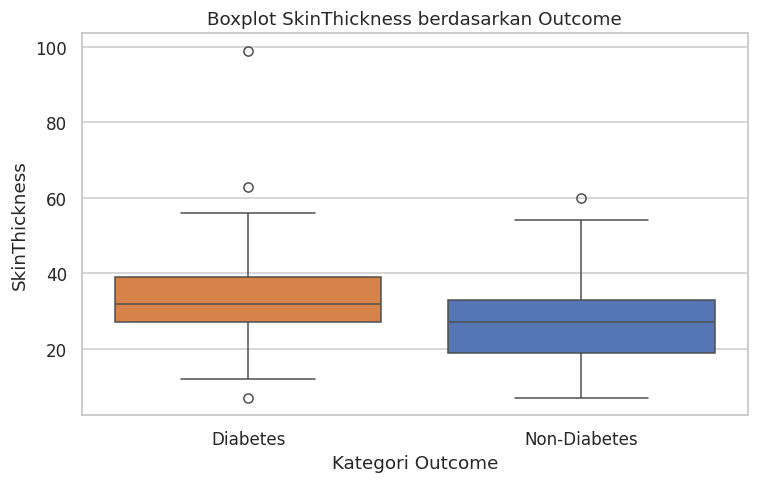

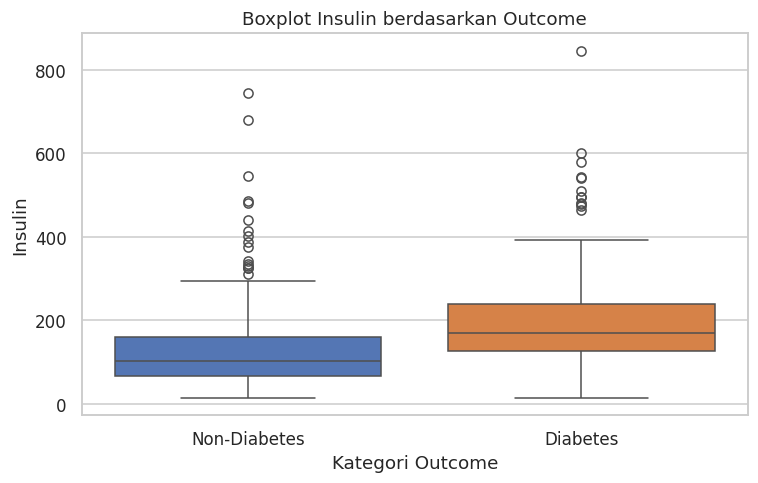

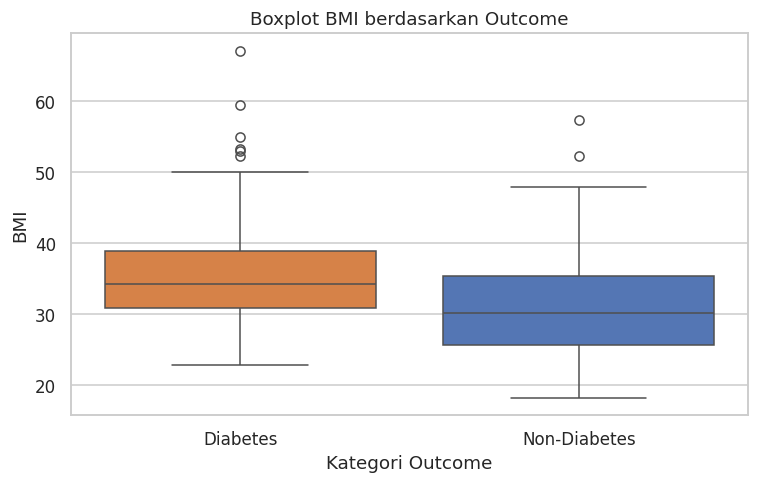

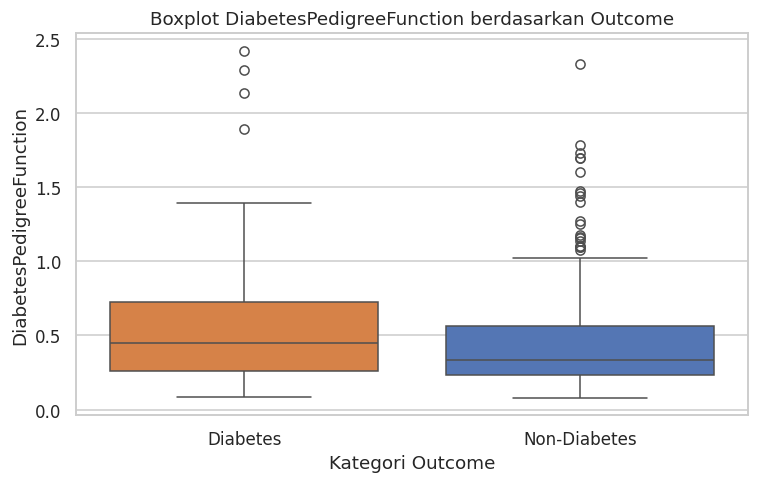

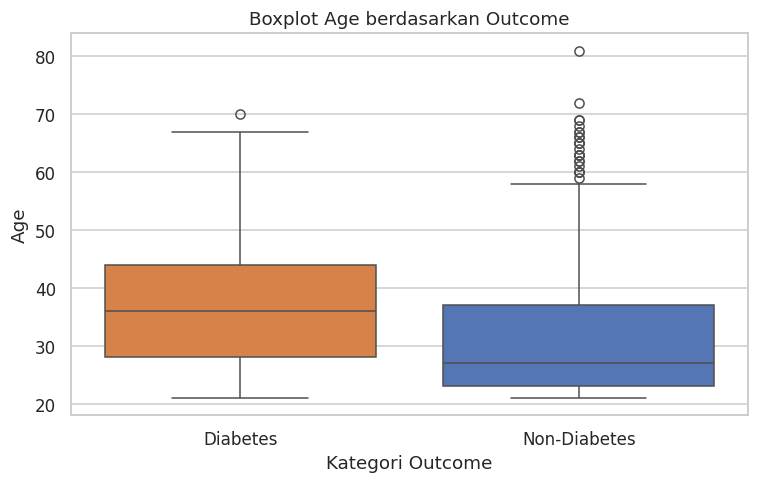

In [ ]:
for kolom in FAKTOR_MEDIS:
    data_plot = df[[kolom, TARGET]].dropna().copy()
    data_plot["Kategori Outcome"] = data_plot[TARGET].map(LABEL_OUTCOME)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.boxplot(data=data_plot, x="Kategori Outcome", y=kolom,
                hue="Kategori Outcome", palette={"Non-Diabetes": "#4472C4", "Diabetes": "#ED7D31"},
                ax=ax)
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.set_title(f"Boxplot {kolom} berdasarkan Outcome")
    ax.set_xlabel("Kategori Outcome")
    ax.set_ylabel(kolom)
    plt.tight_layout()
    simpan_gambar(f"boxplot_{kolom}_berdasarkan_outcome")
    plt.show()

### 3.3 Diagram batang jumlah pasien berdasarkan Outcome

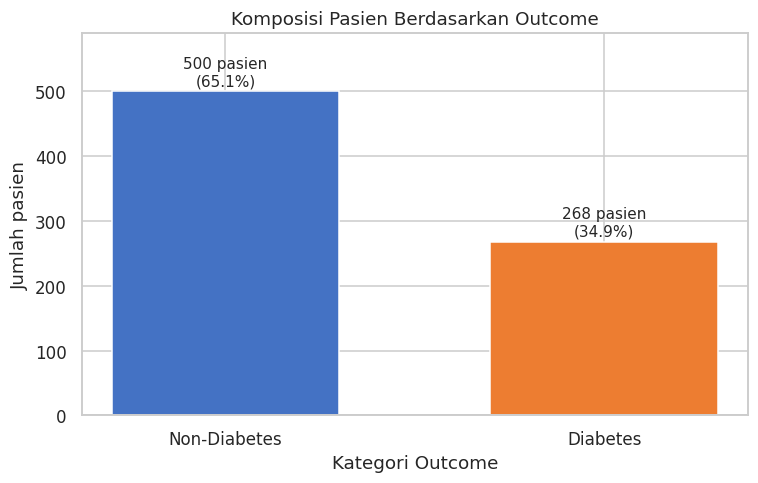

In [ ]:
jumlah = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
persen = jumlah / jumlah.sum() * 100
label = [LABEL_OUTCOME[i] for i in jumlah.index]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(label, jumlah.values,
              color=[WARNA_OUTCOME[i] for i in jumlah.index], width=0.6)
for i, bar in enumerate(bars):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            f"{jumlah.iloc[i]} pasien\n({persen.iloc[i]:.1f}%)",
            ha="center", va="bottom")
ax.set_title("Komposisi Pasien Berdasarkan Outcome")
ax.set_xlabel("Kategori Outcome")
ax.set_ylabel("Jumlah pasien")
ax.set_ylim(0, max(jumlah.values) * 1.18)
plt.tight_layout()
simpan_gambar("diagram_batang_outcome")
plt.show()

### 3.4 Diagram lingkaran proporsi Outcome

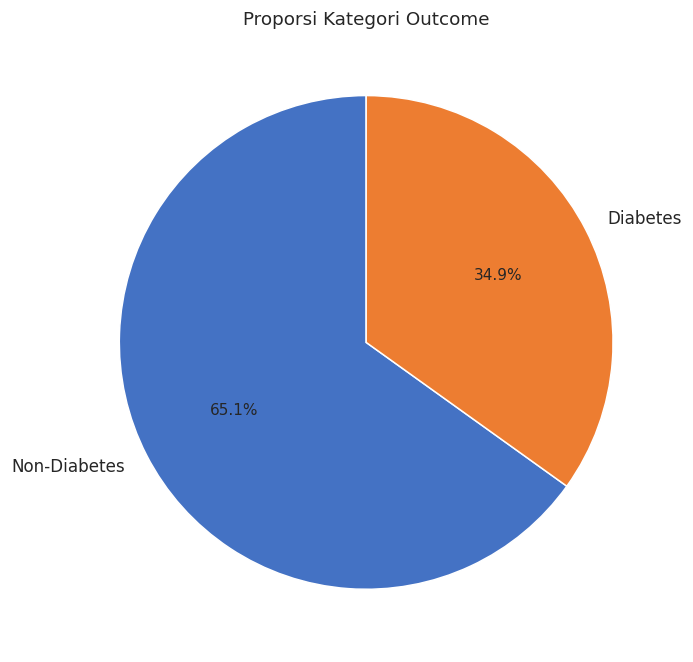

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(jumlah.values, labels=label, autopct="%1.1f%%", startangle=90,
       colors=[WARNA_OUTCOME[i] for i in jumlah.index],
       wedgeprops={"edgecolor": "white", "linewidth": 1})
ax.set_title("Proporsi Kategori Outcome")
plt.tight_layout()
simpan_gambar("diagram_lingkaran_outcome")
plt.show()

### 3.5 Diagram batang rata-rata setiap faktor medis berdasarkan Outcome

Grafik ini membandingkan nilai rata-rata pada dua kategori Outcome untuk setiap faktor medis. Perbandingan ini bersifat deskriptif saja.

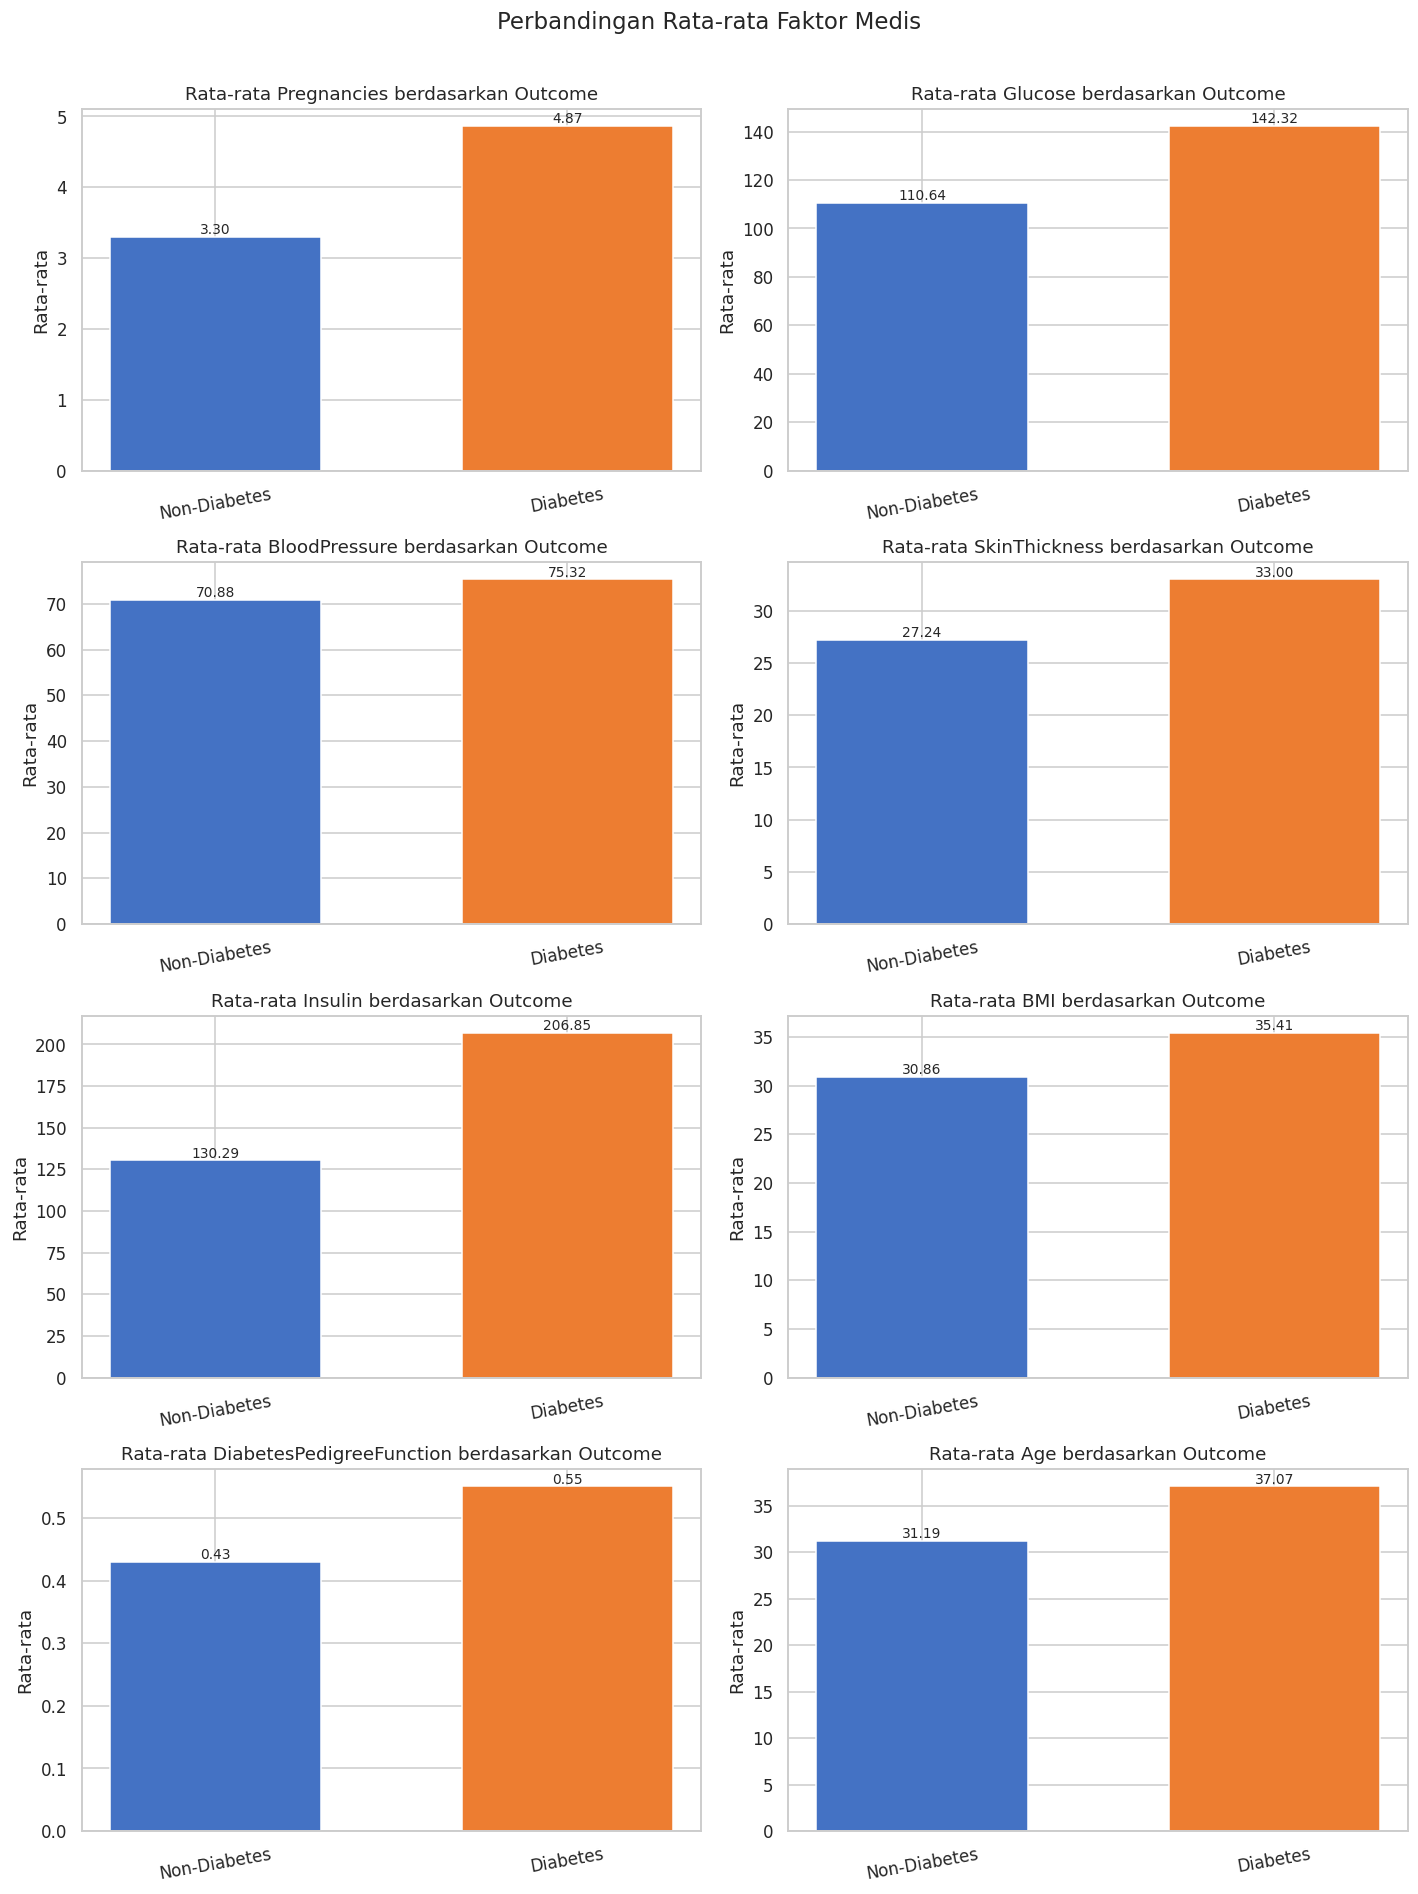

In [ ]:
mean_outcome = df.groupby(TARGET)[FAKTOR_MEDIS].mean().T
mean_outcome = mean_outcome.rename(columns=LABEL_OUTCOME)

fig, axes = plt.subplots(4, 2, figsize=(13, 17))
axes = axes.flatten()
for i, kolom in enumerate(FAKTOR_MEDIS):
    vals = mean_outcome.loc[kolom]
    axes[i].bar(vals.index, vals.values,
                color=["#4472C4", "#ED7D31"], width=0.6)
    axes[i].set_title(f"Rata-rata {kolom} berdasarkan Outcome")
    axes[i].set_ylabel("Rata-rata")
    axes[i].tick_params(axis="x", rotation=10)
    for j, val in enumerate(vals.values):
        axes[i].text(j, val, f"{val:.2f}", ha="center", va="bottom", fontsize=9)
plt.suptitle("Perbandingan Rata-rata Faktor Medis", fontsize=15, y=1.01)
plt.tight_layout()
simpan_gambar("perbandingan_rata_rata_faktor_medis")
plt.show()

### 3.6 Diagram batang median setiap faktor medis berdasarkan Outcome

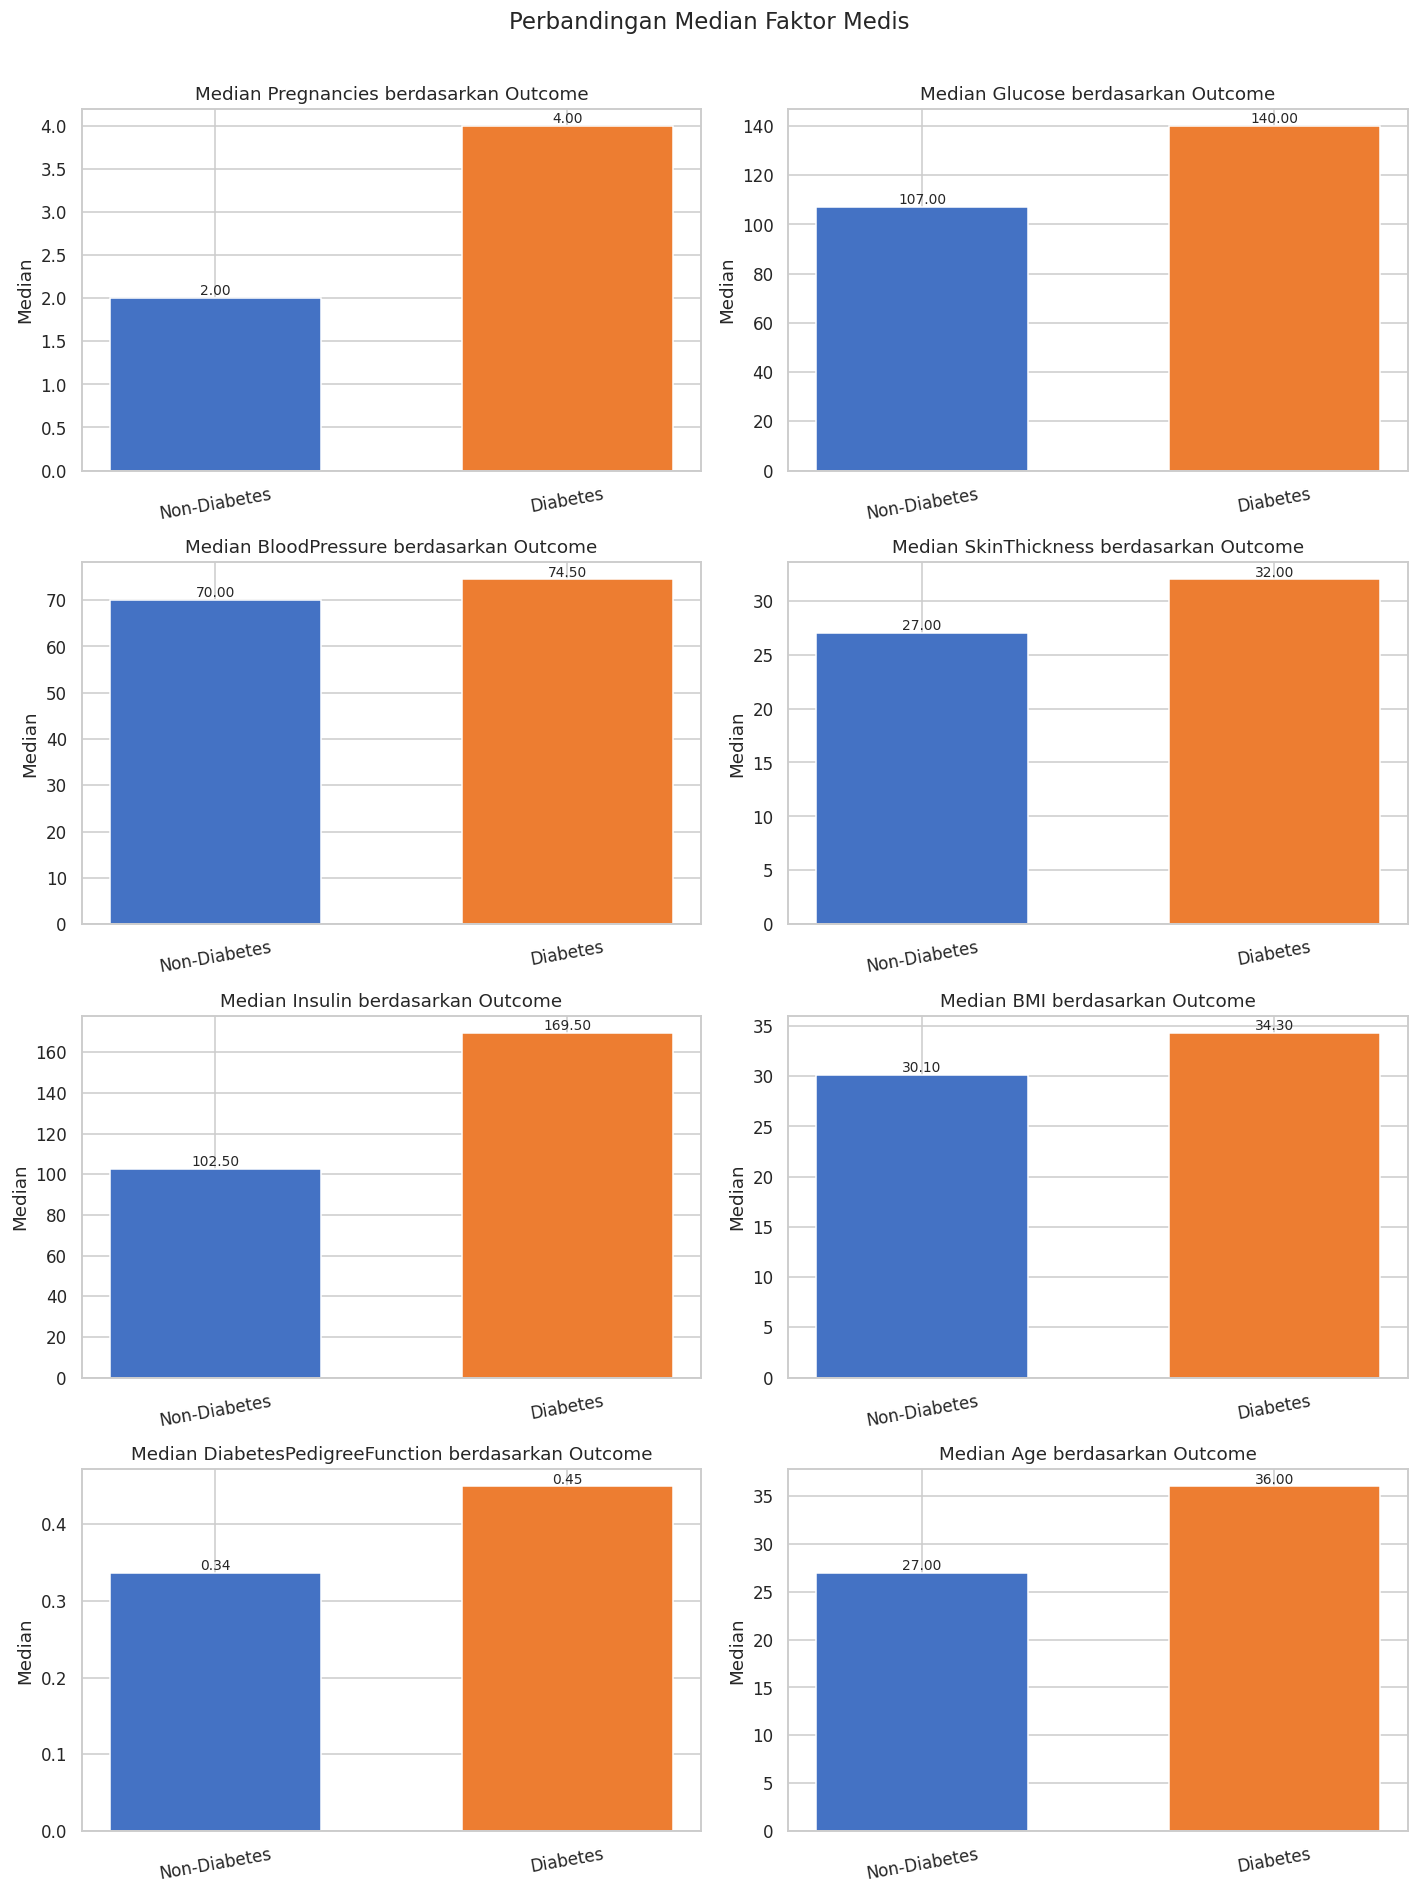

In [ ]:
median_outcome = df.groupby(TARGET)[FAKTOR_MEDIS].median().T
median_outcome = median_outcome.rename(columns=LABEL_OUTCOME)

fig, axes = plt.subplots(4, 2, figsize=(13, 17))
axes = axes.flatten()
for i, kolom in enumerate(FAKTOR_MEDIS):
    vals = median_outcome.loc[kolom]
    axes[i].bar(vals.index, vals.values,
                color=["#4472C4", "#ED7D31"], width=0.6)
    axes[i].set_title(f"Median {kolom} berdasarkan Outcome")
    axes[i].set_ylabel("Median")
    axes[i].tick_params(axis="x", rotation=10)
    for j, val in enumerate(vals.values):
        axes[i].text(j, val, f"{val:.2f}", ha="center", va="bottom", fontsize=9)
plt.suptitle("Perbandingan Median Faktor Medis", fontsize=15, y=1.01)
plt.tight_layout()
simpan_gambar("perbandingan_median_faktor_medis")
plt.show()

## 4. Tabel frekuensi dan proporsi Outcome

In [ ]:
tabel_frekuensi = pd.DataFrame({
    "Outcome": [0, 1],
    "Kategori": [LABEL_OUTCOME[0], LABEL_OUTCOME[1]],
    "Frekuensi": [int((df[TARGET] == 0).sum()), int((df[TARGET] == 1).sum())]
})
tabel_frekuensi["Proporsi"] = tabel_frekuensi["Frekuensi"] / tabel_frekuensi["Frekuensi"].sum()
tabel_frekuensi["Persentase (%)"] = tabel_frekuensi["Proporsi"] * 100
display(tabel_frekuensi.round(4))
tabel_frekuensi.to_csv("tabel/tabel_frekuensi_outcome.csv", index=False)

,Outcome,Kategori,Frekuensi,Proporsi,Persentase (%)
0,0,Non-Diabetes,500,0.651,65.1042
1,1,Diabetes,268,0.349,34.8958


## 5. Ringkasan hasil numerik

In [ ]:
print("Jumlah data:", len(df))
print("Jumlah faktor medis yang dianalisis:", len(FAKTOR_MEDIS))
print("Jumlah Outcome valid:", df[TARGET].notna().sum())
print("\nDistribusi Outcome:")
for nilai in [0, 1]:
    n = int((df[TARGET] == nilai).sum())
    p = n / df[TARGET].notna().sum() * 100
    print(f"{LABEL_OUTCOME[nilai]}: {n} data ({p:.2f}%)")

print("\nMedian tiap faktor medis:")
display(df[FAKTOR_MEDIS].median().to_frame("Median").round(3))

Jumlah data: 768
Jumlah faktor medis yang dianalisis: 8
Jumlah Outcome valid: 768

Distribusi Outcome:
Non-Diabetes: 500 data (65.10%)
Diabetes: 268 data (34.90%)

Median tiap faktor medis:


,Median
Pregnancies,3.000
Glucose,117.000
BloodPressure,72.000
SkinThickness,29.000
Insulin,125.000
BMI,32.300
DiabetesPedigreeFunction,0.372
Age,29.000


## 6. Catatan interpretasi

- `Outcome = 0` berarti kategori non-diabetes dan `Outcome = 1` berarti kategori diabetes pada dataset ini.
- Statistik setiap faktor dihitung dari nilai yang tersedia; jumlah data valid dapat berbeda karena terdapat nilai kosong.
- Skewness menggambarkan kemiringan distribusi. Nilai positif menunjukkan ekor lebih panjang ke kanan, sedangkan nilai negatif menunjukkan ekor lebih panjang ke kiri.
- Kurtosis pada pandas menggunakan excess kurtosis; nilai sekitar 0 mendekati kurtosis distribusi normal menurut definisi excess kurtosis, tetapi ini bukan uji normalitas.
- Boxplot menandai kemungkinan pencilan berdasarkan aturan boxplot. Pencilan tidak otomatis berarti data salah.
- Perbedaan rata-rata atau median antar kategori hanya dideskripsikan. Notebook ini tidak menyimpulkan sebab-akibat dan tidak melakukan pengujian statistik.
- Dataset ini tidak otomatis mewakili prevalensi diabetes pada populasi umum.

## 7. Menyimpan dan mengunduh hasil

Tabel disimpan sebagai CSV di folder `tabel/` dan grafik sebagai PNG di folder `gambar/`. Jalankan sel berikut untuk membuat ZIP yang dapat diunduh.

In [ ]:
import zipfile
with zipfile.ZipFile("hasil_analisis_pima.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["tabel", "gambar"]:
        for root, dirs, names in os.walk(folder):
            for name in names:
                path = os.path.join(root, name)
                z.write(path, arcname=path)
print("Folder tabel/ dan gambar/ telah disimpan.")
print("File ZIP: hasil_analisis_pima.zip")
files.download("hasil_analisis_pima.zip")

Folder tabel/ dan gambar/ telah disimpan.
File ZIP: hasil_analisis_pima.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>